# 4.2 Discrete Probability Distributions

**Goal:** choose a discrete family from the experiment, state its parameters and support, and calculate probabilities without off-by-one errors.

**Prerequisites:** Module 3 and notebook 4.1.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. If needed, install them in your chosen environment with `python3 -m pip install numpy scipy matplotlib`. Open in JupyterLab, Jupyter Notebook, or VS Code with a Python kernel. Use **Restart Kernel and Run All** to reproduce the saved text and figure outputs. Every notebook is self-contained; random examples use a local fixed seed. All data are synthetic or idealized model calculations, and no downloads are needed.

## Contents
1. Bernoulli
2. Binomial
3. Geometric
4. Poisson
5. Negative binomial
6. Hypergeometric
7. Comparison and probabilistic classification
8. Practice and solutions

## Parameter conventions

Here p is a success probability, n a fixed trial count, $\lambda$ a mean event count for a stated exposure, and r a target number of successes. A “success” is simply the designated event, not necessarily a favorable outcome. We use **trial count** for geometric and **failure count** for negative binomial. Both conventions exist; translations are explained below.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate, special

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
rng = np.random.default_rng(2026)

## 1. Bernoulli Distribution

A single binary trial has $X\sim\operatorname{Bernoulli}(p)$ with $0\le p\le1$, support $x\in\{0,1\}$, and
$$P(X=x)=p^x(1-p)^{1-x},\qquad\mathbb E[X]=p,\quad\operatorname{Var}(X)=p(1-p).$$
The endpoint cases are degenerate distributions; interpret their masses directly rather than treating $0^0$ as a mathematical derivation.

**Worked example:** with purchase probability 0.2, $P(X=1)=0.2$, mean 0.2, and variance 0.16. The mean is an event probability, not a possible fractional purchase indicator.

**Logistic regression connection:** conditional on input x, $Y\mid x$ is Bernoulli with $p(x)=1/(1+e^{-w^Tx-b})$. The Bernoulli negative log-likelihood is $-[y\log p+(1-y)\log(1-p)]$. Numerically stable implementations work with log probabilities or logits rather than blindly computing $\log0$.

In [2]:
bernoulli = stats.bernoulli(p=0.2)
print("Bernoulli masses:", bernoulli.pmf([0, 1]))
print("Mean/variance:", bernoulli.mean(), bernoulli.var())
y, p = 1, 0.8
print("Negative log-likelihood for y=1 and p=0.8:", -stats.bernoulli.logpmf(y, p))
assert np.isclose(bernoulli.var(), 0.16)

Bernoulli masses: [0.8 0.2]
Mean/variance: 0.2 0.16
Negative log-likelihood for y=1 and p=0.8: 0.2231435513142097


## 2. Binomial Distribution

$X\sim\operatorname{Binomial}(n,p)$ counts successes in n independent Bernoulli trials with the **same p**. Its support is $0,\ldots,n$, for integer $n\ge0$:
$$P(X=k)=\binom nkp^k(1-p)^{n-k},\quad\mathbb E[X]=np,\quad\operatorname{Var}(X)=np(1-p).$$
The combination factor counts which k trials succeed. A fixed number of trials distinguishes binomial counts from waiting-time distributions.

**Worked example:** 10 independent requests each fail with probability 0.1. The chance exactly two fail is $\binom{10}{2}(0.1)^2(0.9)^8\approx0.19371$; at least one fails with probability $1-0.9^{10}\approx0.65132$.

If probabilities differ by request, their independent sum is generally **Poisson-binomial**, not binomial. Shared outages violate independence and can increase count variability. Sampling a large fraction of a finite population without replacement instead suggests hypergeometric modeling.

In [3]:
binomial = stats.binom(n=10, p=0.1)
manual = math.comb(10, 2)*0.1**2*0.9**8
print("Exactly two failures:", binomial.pmf(2))
print("At least one failure:", binomial.sf(0))
print("Mean/variance:", binomial.mean(), binomial.var())
assert np.isclose(binomial.pmf(2), manual)
assert np.isclose(binomial.pmf(np.arange(11)).sum(), 1)

Exactly two failures: 0.19371024450000024
At least one failure: 0.6513215599000001
Mean/variance: 1.0 0.9


## 3. Geometric Distribution

Let T count the **trial number of the first success** in independent Bernoulli(p) trials, $0<p\le1$:
$$P(T=t)=(1-p)^{t-1}p,\quad t=1,2,\ldots,$$
$$\mathbb E[T]=1/p,\qquad\operatorname{Var}(T)=(1-p)/p^2.$$
SciPy `geom(p)` uses this trial-count convention. The failures-before-success variable $F=T-1$ instead starts at 0 and has mean $(1-p)/p$, with the same variance.

**Worked example:** if p=0.25, the probability first success occurs on trial 3 is $(0.75)^2(0.25)=0.140625$. Probability of needing more than 4 trials is $(0.75)^4\approx0.31641$.

Geometric waiting is **memoryless**: $P(T>s+t\mid T>s)=P(T>t)$ for nonnegative integers s,t. Past failures do not make the next independent trial “due” for success. If success probabilities change over time, this model and memoryless property fail.

In [4]:
geometric = stats.geom(p=0.25)
print("First success on trial 3:", geometric.pmf(3))
print("Need more than four trials:", geometric.sf(4))
print("Expected trial count:", geometric.mean())
print("Expected failures before success:", geometric.mean()-1)
assert np.isclose(geometric.sf(7)/geometric.sf(3), geometric.sf(4))

First success on trial 3: 0.140625
Need more than four trials: 0.31640625000000006
Expected trial count: 4.0
Expected failures before success: 3.0


## 4. Poisson Distribution

$X\sim\operatorname{Poisson}(\lambda)$ has $\lambda\ge0$, support $k=0,1,\ldots$, and, for $\lambda>0$,
$$P(X=k)=e^{-\lambda}\frac{\lambda^k}{k!},\qquad\mathbb E[X]=\operatorname{Var}(X)=\lambda.$$
At $\lambda=0$, all mass is at zero. Specify exposure: if a homogeneous Poisson process has rate r per unit time, the count over duration t has $\lambda=rt$.

**Worked example:** alerts arrive according to a homogeneous Poisson process at rate 3 per hour. In one hour $P(X=2)=e^{-3}3^2/2!\approx0.22404$. Over two hours, the expected count is 6.

Independent increments and a constant rate are assumptions of the homogeneous process motivating this model. A count variable having a Poisson marginal does not, by itself, establish a full Poisson process. Bursts, changing exposure, and heterogeneous rates can create variance larger than the mean. Inspect those mechanisms before choosing a more flexible count model.

In [5]:
poisson = stats.poisson(mu=3)
print("Two alerts in one hour:", poisson.pmf(2))
print("More than five alerts:", poisson.sf(5))
print("Two-hour expected count:", stats.poisson(mu=6).mean())
assert np.isclose(poisson.pmf(2), math.exp(-3)*3**2/math.factorial(2))
assert np.isclose(poisson.mean(), poisson.var())

Two alerts in one hour: 0.22404180765538775
More than five alerts: 0.0839179420313035
Two-hour expected count: 6.0


## 5. Negative Binomial Distribution

Here F counts the **number of failures before the r-th success**, with independent Bernoulli(p) trials, integer $r\ge1$, $0<p\le1$:
$$P(F=k)=\binom{k+r-1}{r-1}p^r(1-p)^k,\quad k=0,1,\ldots,$$
$$\mathbb E[F]=\frac{r(1-p)}p,\qquad\operatorname{Var}(F)=\frac{r(1-p)}{p^2}.$$
The final trial must be a success; among the previous $k+r-1$ trials, choose the other $r-1$ successes. Total trials until the r-th success are $T=F+r$, with mean r/p and the same variance.

**Worked example:** for r=3 and p=0.5, exactly 2 failures before the third success has probability $\binom42(0.5)^3(0.5)^2=0.1875$. The total trial count is 5, not 2.

SciPy `nbinom(n=r,p=p)` counts failures, despite its shape argument being named n. The [official negative binomial documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.nbinom.html) defines this parameterization. At r=1, it corresponds to geometric failures rather than geometric trial count.

A related count-regression parameterization permits real r>0 and writes mean $\mu=r(1-p)/p$ with variance $\mu+\mu^2/r$. This handles overdispersion relative to Poisson, but a fitted dispersion term does not diagnose its substantive cause.

In [6]:
negative_binomial = stats.nbinom(n=3, p=0.5)
print("Two failures before third success:", negative_binomial.pmf(2))
print("Failure-count mean/variance:", negative_binomial.mean(), negative_binomial.var())
print("Total-trial mean:", negative_binomial.mean()+3)
assert np.isclose(negative_binomial.pmf(2), math.comb(4, 2)*0.5**5)
assert np.isclose(stats.nbinom(n=1, p=0.25).pmf(2), stats.geom(p=0.25).pmf(3))

Two failures before third success: 0.1875000000000001
Failure-count mean/variance: 3.0 6.0
Total-trial mean: 6.0


## 6. Hypergeometric Distribution

Draw n items uniformly **without replacement** from a finite population of N items containing K designated successes. X is the number of successes drawn:
$$P(X=k)=\frac{\binom Kk\binom{N-K}{n-k}}{\binom Nn},$$
where $\max(0,n-(N-K))\le k\le\min(n,K)$, and N,K,n are integers with $0\le K,n\le N$. For $N>1$,
$$\mathbb E[X]=n\frac KN,\qquad\operatorname{Var}(X)=n\frac KN\left(1-\frac KN\right)\frac{N-n}{N-1}.$$
The last term is a finite-population correction: dependence from sampling without replacement reduces variance compared with a binomial having p=K/N.

**Worked example:** 4 of 10 components are defective. A uniform sample of 3 without replacement contains exactly 2 defects with probability $\binom42\binom61/\binom{10}{3}=0.3$. Its mean is 1.2 and variance 0.56.

SciPy uses `hypergeom(M=N,n=K,N=n)`, with names that can be confusing. Name the meaning of each argument explicitly rather than copying variable letters from a formula without checking.

In [7]:
hypergeometric = stats.hypergeom(M=10, n=4, N=3)
manual = math.comb(4, 2)*math.comb(6, 1)/math.comb(10, 3)
print("Exactly two defects:", hypergeometric.pmf(2))
print("Mean/variance:", hypergeometric.mean(), hypergeometric.var())
print("Binomial variance with p=0.4:", stats.binom(n=3, p=0.4).var())
assert np.isclose(hypergeometric.pmf(2), manual)
assert np.isclose(hypergeometric.var(), 0.56)
assert np.isclose(hypergeometric.pmf(np.arange(4)).sum(), 1)

Exactly two defects: 0.3
Mean/variance: 1.2 0.56
Binomial variance with p=0.4: 0.7200000000000001


## 7. Compare the discrete families

| Question | Family | Critical assumption/convention |
|---|---|---|
| One binary outcome | Bernoulli | Event coded 1, probability p |
| Success count in n fixed trials | Binomial | Independent trials with common p |
| Trial of first success | Geometric | Independent common-p trials; starts at 1 |
| Event count in an exposure window | Poisson | Chosen mean count; process assumptions if used |
| Failures before r successes | Negative binomial | Failures start at 0; distinguish total trials |
| Success count in finite sampling | Hypergeometric | Uniform sampling without replacement |

The plot displays most of the mass for infinite-support examples, not their entire support. A truncated plotted range does not redefine the distribution.

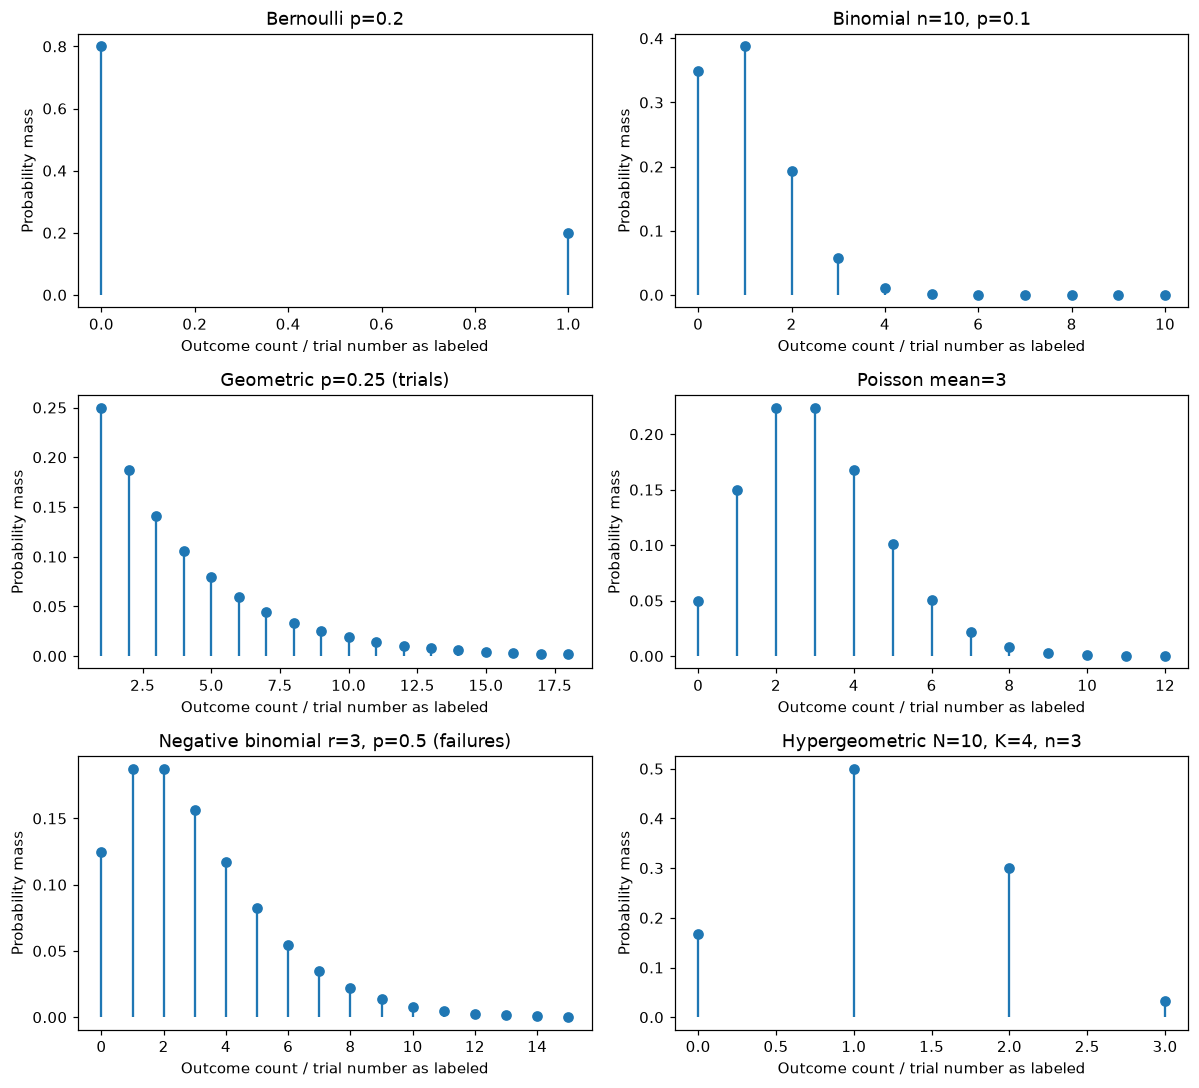

In [8]:
models = [("Bernoulli p=0.2", bernoulli, np.arange(2)),
          ("Binomial n=10, p=0.1", binomial, np.arange(11)),
          ("Geometric p=0.25 (trials)", geometric, np.arange(1, 19)),
          ("Poisson mean=3", poisson, np.arange(13)),
          ("Negative binomial r=3, p=0.5 (failures)", negative_binomial, np.arange(16)),
          ("Hypergeometric N=10, K=4, n=3", hypergeometric, np.arange(4))]
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, (title, model, x) in zip(axes.flat, models):
    ax.stem(x, model.pmf(x), basefmt=" ")
    ax.set(title=title, xlabel="Outcome count / trial number as labeled", ylabel="Probability mass")
fig.tight_layout()
plt.show()

## AI/ML application: Bernoulli Naive Bayes and count likelihoods

Bernoulli Naive Bayes models binary feature presence conditional on the class, multiplying presence and absence probabilities under a conditional-independence approximation. Poisson or negative binomial models can describe event counts, while a binomial likelihood can describe successes out of a known exposure n. Different supports encode different questions: a Poisson model permits counts above n, which a binomial count cannot.

Choose a distribution based on the observation process, support, exposure, and diagnostics rather than the family name alone. In particular, an average count resembling a Poisson mean is not evidence that the full distribution or independence assumptions hold.

## Practice

1. A Bernoulli variable has p=0.3. Find its mean and variance.
2. Under Binomial(5,0.2), find $P(X=0)$ and $P(X\ge1)$.
3. For geometric trial count with p=0.2, find the mean and $P(T=3)$.
4. A Poisson count has mean 2 per hour. What is the mean over 3 hours under a homogeneous process, and $P(X=0)$ for that interval?
5. Negative-binomial failures before r=2 successes with p=0.5: find $P(F=1)$ and expected total trials.
6. A population of 8 contains 3 successes. Draw 2 without replacement. Find $P(X=2)$.
7. Why is the binomial not generally appropriate for a sum of independent Bernoulli variables with different probabilities?
8. Why must a geometric “waiting time” question say whether it counts trials or failures?

## Solutions

1. Mean 0.3; variance $0.3(0.7)=0.21$.
2. $0.8^5=0.32768$; complement 0.67232.
3. Mean 5; probability $(0.8)^2(0.2)=0.128$.
4. Mean 6; zero-count probability $e^{-6}\approx0.002479$.
5. $\binom21(0.5)^2(0.5)=0.25$; total-trial expectation r/p=4.
6. $\binom32\binom50/\binom82=3/28\approx0.107143$.
7. Common p is a binomial assumption; differing independent probabilities instead define a Poisson-binomial sum.
8. The supports start at 1 and 0, respectively, and their means differ by one even though their variances agree.

**Readiness check:** state support and assumptions, translate library parameter names, and verify endpoint inclusion before using CDF differences.

**Next:** [4.3 Continuous Probability Distributions](3_Continuous-Probability-Distributions.ipynb).